# 02 · RQ1: Does JogjaPulse agree with Google's mobility data?

JogjaPulse (advertising-SDK device pings, k = 5) and Google Community Mobility Reports (Location History, differential privacy) are collected and processed independently ([docs/related_datasets.md](../docs/related_datasets.md)). If their day-to-day changes move together, that is external validation of JogjaPulse.

Method, in both sources: compare each day with the median of the same weekday 1 and 2 weeks before and after, leaving out the day itself and holidays. JogjaPulse measures use log(value / baseline); Google uses value − baseline, since it is already a % change against a weekday-specific 2020 baseline. Correlation is Spearman, over DIY-level days.

Limits that apply to every result here: Google is only available for the whole province; devices are not people; the JogjaPulse panel shrinks and shifts geography over time, which is why only shares and deviations are compared.

Figures are saved to `reports/figures/rq1_*.png`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from config import (CALENDAR_CSV, FIGURES as FIG, GOOGLE_CATEGORIES, PANEL_SEGMENTS,
                    PLACES_CSV, PROCESSED)
from build_features import weekday_deviation

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "axes.titleweight": "bold", "axes.titlesize": 13})
pd.set_option("display.width", 160, "display.max_columns", 20)
JP_COL, G_COL = "#0F766E", "#C2410C"   # slide colours (presentation/slides_plan.md)
FIGSIZE = (12.8, 7.2)                   # 1920 x 1080 at 150 dpi

daily = pd.read_parquet(PROCESSED / "daily_diy.parquet").set_index("date")
grid = pd.read_parquet(PROCESSED / "grid_daily.parquet",
                       columns=["cell_id", "date", "centroid_lat", "centroid_lon",
                                "lattice_artifact", "share_of_diy_day"])
hourly = pd.read_parquet(PROCESSED / "hourly_kapanewon.parquet",
                         columns=["date", "hour", "kab_kota", "kapanewon_code", "kapanewon", "n_maids"])
# daily_diy stores dates as ns, the others as us; align them so joins on date match.
for df in (grid, hourly):
    df["date"] = df["date"].astype("datetime64[ns]")
places = pd.read_csv(PLACES_CSV)
cal = pd.read_csv(CALENDAR_CSV, parse_dates=["date"])
holidays = daily.is_holiday

assert len(daily) == 151 and daily.index.is_unique
G_DEV = [f"dev_g_{c}" for c in GOOGLE_CATEGORIES]

def savefig(fig, name):
    fig.savefig(FIG / f"rq1_{name}.png")

def shade_holidays(ax, label=True):
    for d, name in daily.loc[daily.is_holiday, "holiday_name"].items():
        ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color="grey", alpha=.18, lw=0)
        if label:
            ax.text(d, 1.01, name.split(" (")[0], rotation=45, fontsize=8, color="dimgrey",
                    transform=ax.get_xaxis_transform(), ha="left", va="bottom")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%Y"))

print(f"{len(daily)} days, {daily.is_holiday.sum()} holidays, {len(places)} OSM places")

151 days, 7 holidays, 17 OSM places


## 1. Baseline check

Before 10 Nov the baseline was a centred rolling median over 5 same-weekdays *including the day itself*. When a day is the middle value of its own window, its deviation is exactly 0. Holidays cluster (25 Dec and 1 Jan are both Saturdays), so a holiday could become its own median and disappear. The cell below recomputes the old version only to compare it with the pipeline's current method.

In [2]:
def old_weekday_deviation(s, log_ratio):
    # Previous method, kept here only for this comparison.
    out = pd.Series(index=s.index, dtype=float)
    for wd in range(7):
        idx = s.index[s.index.day_of_week == wd]
        base = s.loc[idx].rolling(5, center=True, min_periods=3).median()
        out.loc[idx] = np.log(s.loc[idx] / base) if log_ratio else s.loc[idx] - base
    return out

old_jp = old_weekday_deviation(daily.jp_share_gunungkidul, True)
check = pd.DataFrame({
    "exact zeros (old)": [(old_jp == 0).sum()],
    "exact zeros (current)": [(daily.dev_jp_share_gunungkidul == 0).sum()],
    "days without baseline (current)": [daily.dev_jp_share_gunungkidul.isna().sum()],
}, index=["Gunungkidul share"])
display(check)

sat = daily.loc["2021-12-18":"2022-01-08"]
sat = sat[sat.day_of_week == 5]
display(pd.DataFrame({"holiday": sat.holiday_name.fillna(""),
                      "share (%)": (sat.jp_share_gunungkidul * 100).round(2),
                      "old deviation (%)": (old_jp.loc[sat.index] * 100).round(1),
                      "current deviation (%)": (sat.dev_jp_share_gunungkidul * 100).round(1)}))

zeros_g = (daily[G_DEV] == 0).sum()
print("Exact zeros left in Google deviations (whole-number % values can equal the median):")
print(zeros_g.to_string())

,exact zeros (old),exact zeros (current),days without baseline (current)
Gunungkidul share,36,0,2


,holiday,share (%),old deviation (%),current deviation (%)
date,,,,
2021-12-18,,5.60,-12.3,-15.4
2021-12-25,Christmas,6.33,0.0,8.7
2022-01-01,New Year,6.70,14.3,17.9
2022-01-08,,5.81,0.0,9.9


Exact zeros left in Google deviations (whole-number % values can equal the median):
dev_g_retail_and_recreation     6
dev_g_grocery_and_pharmacy      2
dev_g_parks                     0
dev_g_transit_stations          6
dev_g_workplaces                9
dev_g_residential              28


## 2. Place-based JogjaPulse measures

Google's categories are place types, so the closest JogjaPulse match is the share of DIY presence at those places.

- Transit and malls: 500 m grid cells whose centroid lies within 500 m of an OpenStreetMap point (`src/fetch_places.py`), each cell assigned to its nearest place. Cells must be published on at least 140 of 151 days; otherwise a suppressed day (fewer than 5 devices) would look like a drop.
- Beaches: almost every beach cell is suppressed on most days (table below), so beaches use the coastal tourist kapanewon from the hourly table instead.

These are proxies, not visits to the places themselves. After the 140-day rule the transit measure is 7 cells around Tugu, Lempuyangan and Jombor, and the mall measure is 9 cells at 5 malls (printed below). A 500 m cell also holds the streets and housing around the station or mall, so results apply to these selected cells, not to transit or retail activity in DIY as a whole.

In [3]:
RADIUS_M = 500
MIN_DAYS_PUBLISHED = 140
M_PER_DEG = 111_000

cells = grid.drop_duplicates("cell_id").set_index("cell_id")[["centroid_lat", "centroid_lon", "lattice_artifact"]]
days_published = grid.groupby("cell_id").date.nunique()

def dist_m(lat, lon):
    dy = (cells.centroid_lat - lat) * M_PER_DEG
    dx = (cells.centroid_lon - lon) * M_PER_DEG * np.cos(np.radians(lat))
    return np.hypot(dx, dy)

D = pd.DataFrame({r["name"]: dist_m(r.lat, r.lon) for _, r in places.iterrows()})
nearest = D.idxmin(axis=1)
cell_place = (pd.DataFrame({"place": nearest, "dist_m": D.min(axis=1)})
              .query("dist_m <= @RADIUS_M")
              .join(places.set_index("name").group, on="place")
              .join(days_published.rename("days_published"))
              .join(cells.lattice_artifact))
assert not cell_place.lattice_artifact.any(), "a place cell is a lattice artifact"

coverage = (cell_place.groupby(["group", "place"])
            .agg(cells=("dist_m", "size"), min_days=("days_published", "min"),
                 max_days=("days_published", "max"))
            .reindex(places.set_index(["group", "name"]).index))
display(coverage)

cells  min_days  max_days
group   name                                                                         
transit Stasiun Yogyakarta (Tugu)                               2       150       151
        Stasiun Lempuyangan                                     3       149       151
        Terminal Giwangan                                       4        79       139
        Terminal Jombor                                         3       128       144
        Bandara Adisutjipto                                     2        54       122
        Yogyakarta International Airport (rail station ...      4        10        78
mall    Malioboro Mall                                          3       151       151
        Plaza Ambarrukmo                                        2       143       149
        Jogja City Mall                                         3        84       140
        Galeria Mall                                            2       151       151
        Pakuwon Mall Jogja                                      3       116       147
beach   Pantai Parangtritis                                     1        14        14
        Pantai Depok                                            1         1         1
        Pantai Baron                                            2         2         3
        Pantai Drini                                            1         1         1
        Pantai Indrayanti                                       2         1         8
        Pantai Glagah                                           2        11        78

In [4]:
used = cell_place[cell_place.group.isin(["transit", "mall"]) &
                  (cell_place.days_published >= MIN_DAYS_PUBLISHED)]
print("Cells used:", used.groupby("group").size().to_dict())
display(used.groupby(["group", "place"]).size().rename("cells used").to_frame())

g = grid.merge(used[["group"]], left_on="cell_id", right_index=True)
# A suppressed cell-day had fewer than 5 devices; counting it as 0 share changes the sum by a negligible amount.
place_share = g.pivot_table(index="date", columns="group", values="share_of_diy_day", aggfunc="sum").fillna(0)

COASTAL = ["KRETEK", "TANJUNGSARI", "TEPUS"]   # Parangtritis/Depok, Baron/Drini, Indrayanti
codes = hourly.drop_duplicates("kapanewon_code").set_index("kapanewon_code")
coastal_codes = codes.index[codes.kapanewon.isin(COASTAL)]
assert len(coastal_codes) == len(COASTAL), "coastal names must be unique"
coastal_share = (hourly[hourly.kapanewon_code.isin(coastal_codes)].groupby("date").n_maids.sum()
                 / hourly.groupby("date").n_maids.sum())

jp_place = pd.DataFrame({"jp_share_transit_cells": place_share["transit"],
                         "jp_share_mall_cells": place_share["mall"],
                         "jp_share_coastal_kapanewon": coastal_share}).reindex(daily.index)
assert jp_place[["jp_share_transit_cells", "jp_share_mall_cells"]].notna().all().all()
# Days when all three coastal kapanewon were suppressed every hour stay NaN rather than 0,
# because log(0) has no meaning and the true value is only "fewer than 5 devices".
print("Days with all coastal kapanewon suppressed:",
      jp_place.index[jp_place.jp_share_coastal_kapanewon.isna()].strftime("%d %b %Y").tolist())
dev_place = weekday_deviation(jp_place, log_ratio=True, holidays=holidays).add_prefix("dev_")
(jp_place * 100).describe().round(2)

Cells used: {'mall': 9, 'transit': 7}


cells used
group   place                                
mall    Galeria Mall                        2
        Jogja City Mall                     1
        Malioboro Mall                      3
        Pakuwon Mall Jogja                  1
        Plaza Ambarrukmo                    2
transit Stasiun Lempuyangan                 3
        Stasiun Yogyakarta (Tugu)           2
        Terminal Jombor                     2

Days with all coastal kapanewon suppressed: ['19 Apr 2022']


,jp_share_transit_cells,jp_share_mall_cells,jp_share_coastal_kapanewon
count,151.00,151.00,150.00
mean,0.90,1.61,0.80
std,0.38,0.52,0.37
min,0.21,0.56,0.05
25%,0.56,1.27,0.58
50%,0.99,1.64,0.78
75%,1.19,1.97,1.00
max,1.76,2.83,2.34


## 3. Correlation matrix

Rows: JogjaPulse deviations. Columns: Google deviations. Each Google category has a pre-chosen JogjaPulse match (table in section 3b); the full matrix shows whether the matches stand out or whether everything correlates a little. The matrix uses only days where every measure has a value, so its day count can be lower than in 3b (the coastal kapanewon are suppressed on 19 Apr, which also leaves some neighbouring days without two valid baseline values).

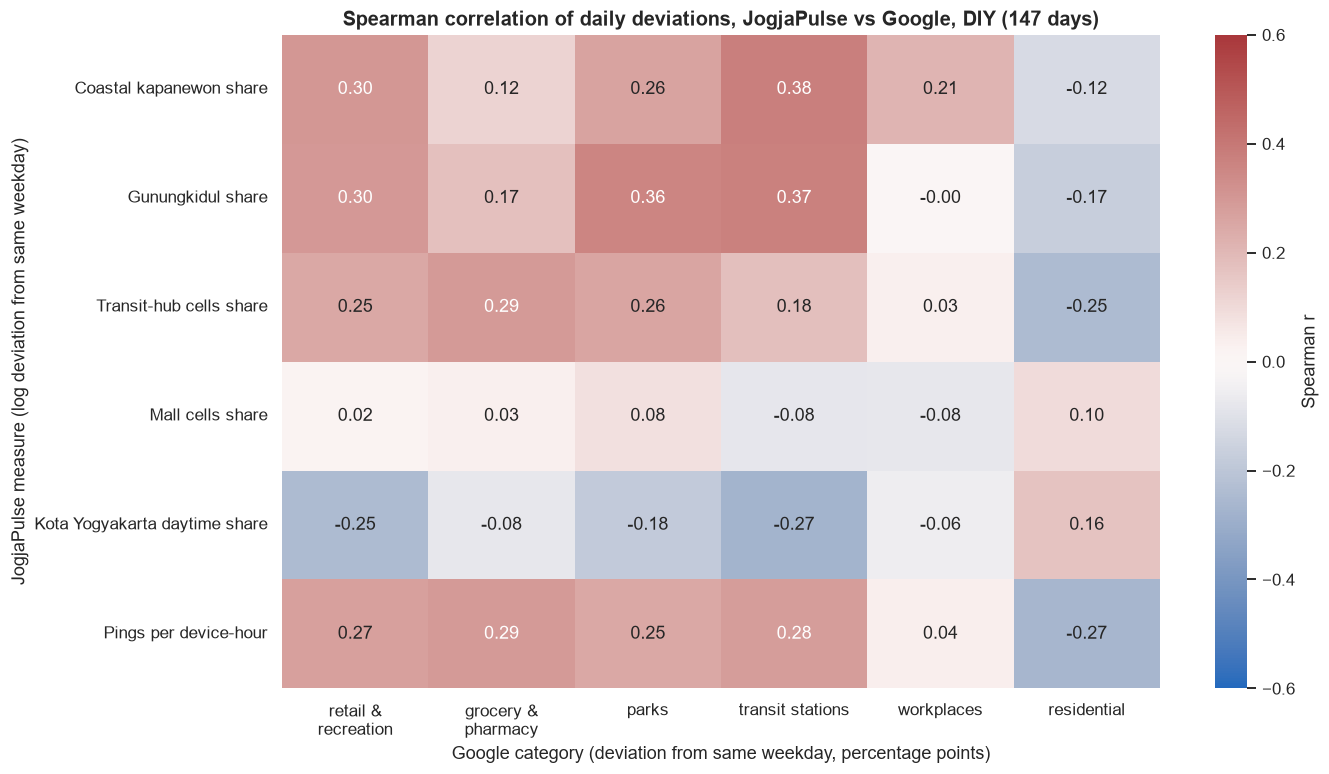

In [5]:
JP_DEV = {
    "dev_jp_share_coastal_kapanewon": "Coastal kapanewon share",
    "dev_jp_share_gunungkidul": "Gunungkidul share",
    "dev_jp_share_transit_cells": "Transit-hub cells share",
    "dev_jp_share_mall_cells": "Mall cells share",
    "dev_jp_city_daytime_share": "Kota Yogyakarta daytime share",
    "dev_jp_pings_per_device_hour": "Pings per device-hour",
}
dev = daily.join(dev_place)
pairs_df = dev[list(JP_DEV) + G_DEV].dropna()
n_days = len(pairs_df)
corr = pairs_df.corr(method="spearman").loc[list(JP_DEV), G_DEV]

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.heatmap(corr.rename(index=JP_DEV, columns=lambda c: c[6:].replace("_and_", " &\n").replace("_", " ")),
            annot=True, fmt=".2f", cmap="vlag", vmin=-.6, vmax=.6, ax=ax,
            cbar_kws={"label": "Spearman r"}, annot_kws={"size": 12})
ax.set_xlabel("Google category (deviation from same weekday, percentage points)")
ax.set_ylabel("JogjaPulse measure (log deviation from same weekday)")
ax.set_title(f"Spearman correlation of daily deviations, JogjaPulse vs Google, DIY ({n_days} days)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
savefig(fig, "corr_heatmap")
plt.show()

### 3b. Matched pairs with confidence intervals

Days are not independent (holiday periods last several days), so the 95% interval comes from a moving-block bootstrap with 14-day blocks.

In [6]:
MATCHES = [
    ("dev_jp_share_coastal_kapanewon", "dev_g_parks"),
    ("dev_jp_share_gunungkidul", "dev_g_parks"),
    ("dev_jp_share_transit_cells", "dev_g_transit_stations"),
    ("dev_jp_share_mall_cells", "dev_g_retail_and_recreation"),
    ("dev_jp_pings_per_device_hour", "dev_g_retail_and_recreation"),
    ("dev_jp_pings_per_device_hour", "dev_g_residential"),
]
BLOCK, N_BOOT = 14, 2000
rng = np.random.default_rng(0)

def block_bootstrap_ci(x, y):
    n = len(x)
    starts = np.arange(n - BLOCK + 1)
    rs = []
    for _ in range(N_BOOT):
        idx = np.concatenate([np.arange(s, s + BLOCK) for s in rng.choice(starts, n // BLOCK + 1)])[:n]
        rs.append(pd.Series(x[idx]).corr(pd.Series(y[idx]), method="spearman"))
    return np.percentile(rs, [2.5, 97.5])

rows = []
for j, gcol in MATCHES:
    xy = dev[[j, gcol]].dropna()
    r = xy[j].corr(xy[gcol], method="spearman")
    lo, hi = block_bootstrap_ci(xy[j].to_numpy(), xy[gcol].to_numpy())
    rows.append({"JogjaPulse": JP_DEV[j], "Google": gcol[6:], "n": len(xy),
                 "r": round(r, 2), "95% CI": f"{lo:.2f} to {hi:.2f}"})
matched = pd.DataFrame(rows)
matched

,JogjaPulse,Google,n,r,95% CI
0,Coastal kapanewon share,parks,147,0.26,-0.05 to 0.52
1,Gunungkidul share,parks,149,0.37,0.11 to 0.56
2,Transit-hub cells share,transit_stations,149,0.19,-0.07 to 0.41
3,Mall cells share,retail_and_recreation,149,0.03,-0.14 to 0.21
4,Pings per device-hour,retail_and_recreation,149,0.27,0.12 to 0.53
5,Pings per device-hour,residential,149,-0.26,-0.58 to 0.02


## 4. Why the adjustment matters

Correlating raw daily levels mixes in two trends that have nothing to do with each other: the JogjaPulse panel shrinks and shifts toward the city, while Google's categories drift as the pandemic eases. The left bars show what a naive comparison would report.

,Raw daily levels,Deviation from same weekday
pair,,
Total device-hours vs residential,-0.77,NaN
Gunungkidul share vs parks,0.37,0.37
Transit cells vs transit stations,-0.39,0.19
Mall cells vs retail & recreation,-0.34,0.03


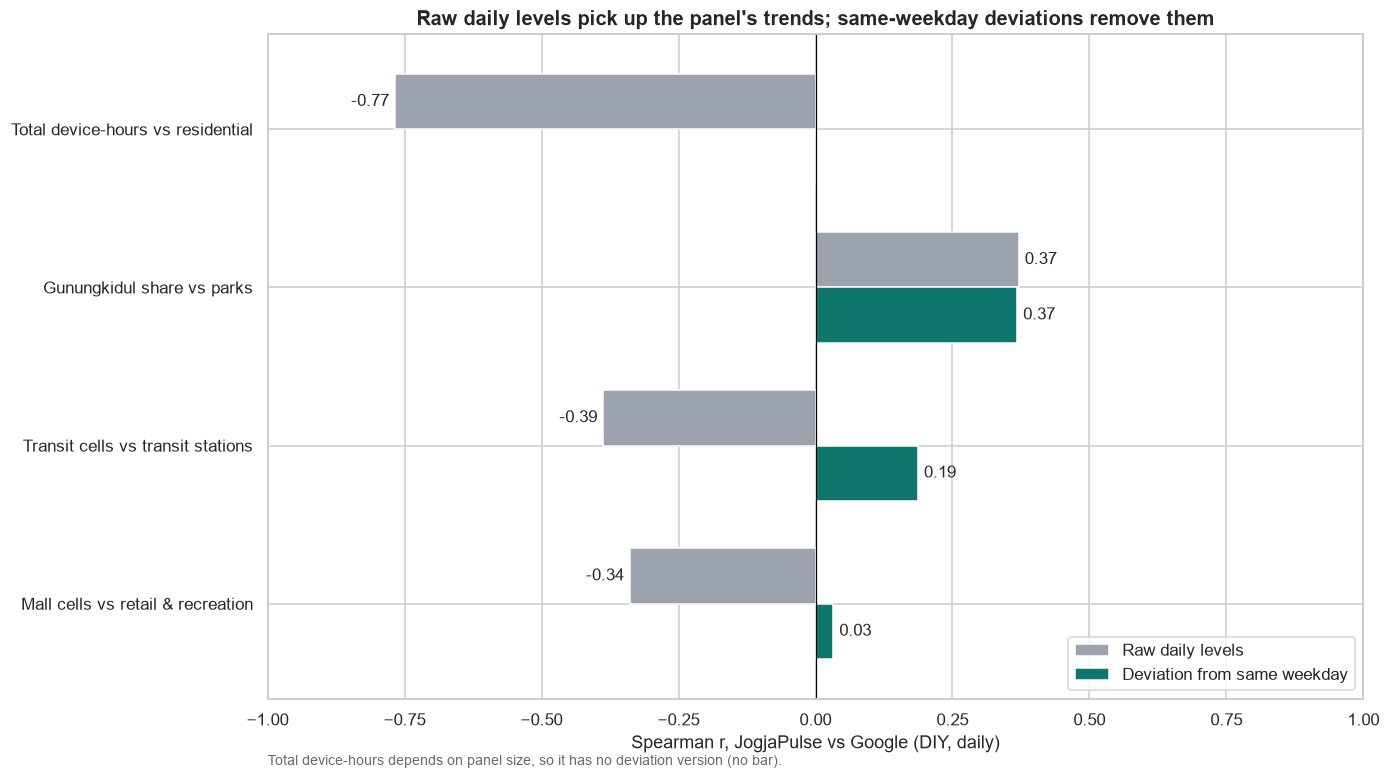

In [7]:
levels = daily.join(jp_place)
SHOW = [("jp_presence_total", "g_residential", "Total device-hours vs residential"),
        ("jp_share_gunungkidul", "g_parks", "Gunungkidul share vs parks"),
        ("jp_share_transit_cells", "g_transit_stations", "Transit cells vs transit stations"),
        ("jp_share_mall_cells", "g_retail_and_recreation", "Mall cells vs retail & recreation")]
comp = pd.DataFrame([{
    "pair": label,
    "Raw daily levels": levels[j].corr(levels[gc], method="spearman"),
    "Deviation from same weekday": (dev[[f"dev_{j}", f"dev_{gc}"]].dropna().corr(method="spearman").iloc[0, 1]
                                    if f"dev_{j}" in dev else np.nan),
} for j, gc, label in SHOW]).set_index("pair")
display(comp.round(2))

fig, ax = plt.subplots(figsize=FIGSIZE)
comp.plot.barh(ax=ax, color=["#9CA3AF", JP_COL], width=.7)
for c, col in zip(ax.containers, comp.columns):
    ax.bar_label(c, labels=["" if np.isnan(v) else f"{v:.2f}" for v in comp[col]], padding=4, fontsize=11)
ax.axvline(0, color="black", lw=.8)
ax.set_xlim(-1, 1)
ax.invert_yaxis()
ax.set_xlabel("Spearman r, JogjaPulse vs Google (DIY, daily)")
ax.set_ylabel("")
ax.set_title("Raw daily levels pick up the panel's trends; same-weekday deviations remove them")
ax.text(0, -0.1, "Total device-hours depends on panel size, so it has no deviation version (no bar).",
        transform=ax.transAxes, fontsize=9, color="dimgrey")
ax.legend(loc="lower right")
fig.tight_layout()
savefig(fig, "raw_vs_adjusted")
plt.show()

## 5. Daily deviation series

The pair with the strongest support in section 3b (Gunungkidul share vs parks) over time, with holidays shaded. Both axes are deviations from a normal day of the same weekday.

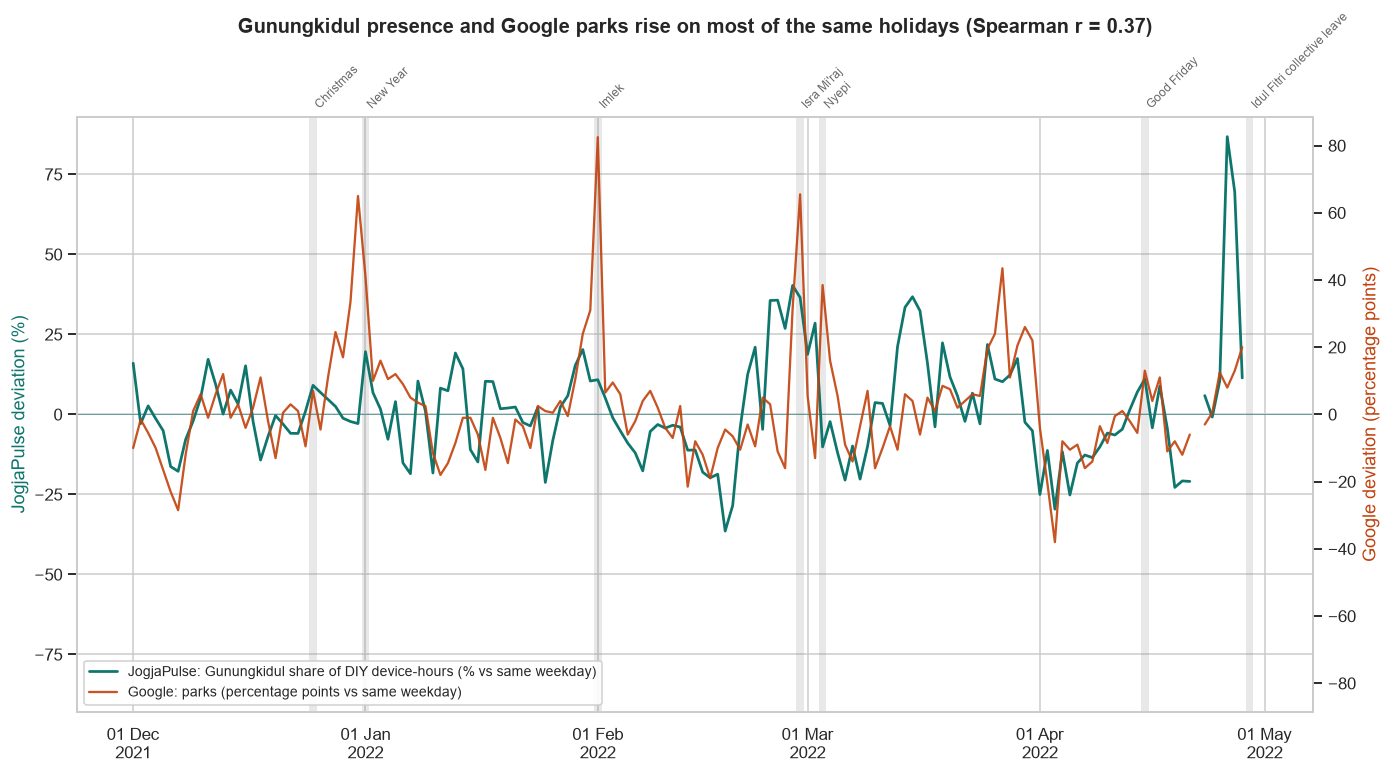

In [8]:
j, gc = "dev_jp_share_gunungkidul", "dev_g_parks"
s = dev[[j, gc]]
r_main = s.dropna().corr(method="spearman").iloc[0, 1]

fig, ax1 = plt.subplots(figsize=FIGSIZE)
ax1.plot(s.index, (np.exp(s[j]) - 1) * 100, color=JP_COL, lw=1.8,
         label="JogjaPulse: Gunungkidul share of DIY device-hours (% vs same weekday)")
ax1.set_ylabel("JogjaPulse deviation (%)", color=JP_COL)
ax1.axhline(0, color=JP_COL, lw=.6, alpha=.6)
ax2 = ax1.twinx()
ax2.plot(s.index, s[gc], color=G_COL, lw=1.5, alpha=.9,
         label="Google: parks (percentage points vs same weekday)")
ax2.set_ylabel("Google deviation (percentage points)", color=G_COL)
ax2.grid(False)
# Align the two zero lines so above/below zero reads the same on both axes.
lim1, lim2 = np.abs(ax1.get_ylim()).max(), np.abs(ax2.get_ylim()).max()
ax1.set_ylim(-lim1, lim1); ax2.set_ylim(-lim2, lim2)
shade_holidays(ax1)
ax1.set_title(f"Gunungkidul presence and Google parks rise on most of the same holidays (Spearman r = {r_main:.2f})",
              pad=55)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="lower left", fontsize=9, framealpha=.9)
fig.tight_layout()
savefig(fig, "deviation_series")
plt.show()

## 6. Stability across panel segments

The JogjaPulse panel changes at 1 Jan and 16 Feb 2022. If agreement only exists in one segment, it could come from the panel rather than from behaviour.

In [9]:
seg_rows = []
for j, gcol in MATCHES[:4]:
    for seg in PANEL_SEGMENTS:
        xy = dev.loc[dev.panel_segment == seg, [j, gcol]].dropna()
        seg_rows.append({"pair": f"{JP_DEV[j]} vs {gcol[6:]}", "segment": seg, "n": len(xy),
                         "r": round(xy[j].corr(xy[gcol], method="spearman"), 2)})
by_segment = pd.DataFrame(seg_rows)
display(by_segment.pivot(index="pair", columns="segment", values="r")[PANEL_SEGMENTS])
by_segment.groupby("segment", observed=True).n.agg(["min", "max"]).rename(columns={"min": "n min", "max": "n max"})

segment,S1 Dec,S2 1 Jan-15 Feb,S3 16 Feb-Apr
pair,,,
Coastal kapanewon share vs parks,0.08,0.10,0.41
Gunungkidul share vs parks,0.17,0.25,0.46
Mall cells share vs retail_and_recreation,0.39,0.10,-0.15
Transit-hub cells share vs transit_stations,0.17,0.24,0.21


,n min,n max
segment,,
S1 Dec,31,31
S2 1 Jan-15 Feb,46,46
S3 16 Feb-Apr,70,72


## 7. Holidays one by one

For each holiday: does each source move above or below a normal day of the same weekday? JogjaPulse values are % deviation of the share; Google values are percentage points.

In [10]:
H_COLS = {"dev_jp_share_gunungkidul": "JP Gunungkidul (%)",
          "dev_jp_share_coastal_kapanewon": "JP coastal (%)", "dev_g_parks": "G parks (pp)",
          "dev_jp_share_transit_cells": "JP transit cells (%)", "dev_g_transit_stations": "G transit (pp)",
          "dev_jp_share_mall_cells": "JP mall cells (%)", "dev_g_retail_and_recreation": "G retail (pp)"}
hol = dev.loc[dev.is_holiday, ["holiday_name"] + list(H_COLS)].copy()
for c in H_COLS:
    if c.startswith("dev_jp"):
        hol[c] = (np.exp(hol[c]) - 1) * 100
hol = hol.rename(columns=H_COLS).round(1)
hol.index = hol.index.strftime("%a %d %b %Y")
display(hol)

same_sign = {}
for a, b in [("JP Gunungkidul (%)", "G parks (pp)"), ("JP coastal (%)", "G parks (pp)"),
             ("JP transit cells (%)", "G transit (pp)"),
             ("JP mall cells (%)", "G retail (pp)")]:
    ok = hol[[a, b]].dropna()
    same_sign[f"{a} / {b}"] = f"{int((np.sign(ok[a]) == np.sign(ok[b])).sum())} of {len(ok)}"
pd.Series(same_sign, name="holidays with the same sign").to_frame()

,holiday_name,JP Gunungkidul (%),JP coastal (%),G parks (pp),JP transit cells (%),G transit (pp),JP mall cells (%),G retail (pp)
date,,,,,,,,
Sat 25 Dec 2021,Christmas,9.1,102.8,7.0,9.2,-11.0,-44.8,0.0
Sat 01 Jan 2022,New Year,19.6,-8.2,41.0,39.5,-6.0,125.5,-6.0
Tue 01 Feb 2022,Imlek (Chinese New Year 2573),10.8,35.9,82.5,41.9,24.0,41.9,18.0
Mon 28 Feb 2022,Isra Mi'raj,36.5,12.8,65.5,6.0,24.0,40.5,10.0
Thu 03 Mar 2022,Nyepi (Saka New Year 1944),-10.2,16.8,38.5,-1.6,12.0,5.2,9.0
Fri 15 Apr 2022,Good Friday,11.1,1.3,13.0,-4.9,-1.0,13.3,4.0
Fri 29 Apr 2022,Idul Fitri collective leave,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,holidays with the same sign
JP Gunungkidul (%) / G parks (pp),5 of 6
JP coastal (%) / G parks (pp),5 of 6
JP transit cells (%) / G transit (pp),3 of 6
JP mall cells (%) / G retail (pp),4 of 6


## 8. Workplaces and residential

Google's workplaces and residential categories describe commuting. The JogjaPulse candidate is how differently devices are spread across kapanewon by day (09–17) and by night (00–05): the dissimilarity index, ½ Σ |day share − night share|. It should be higher on working days if JogjaPulse captures commuting.

In [11]:
def kapanewon_distribution(hours):
    x = (hourly[hourly.hour.isin(hours)]
         .groupby(["date", "kapanewon_code"]).n_maids.mean().unstack(fill_value=0))
    return x.div(x.sum(axis=1), axis=0)

day_d, night_d = kapanewon_distribution(range(9, 18)).align(kapanewon_distribution(range(0, 6)), fill_value=0)
dissim = 0.5 * (day_d - night_d).abs().sum(axis=1)

by_weekday = (dissim.groupby(dissim.index.day_name()).mean()
              .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))
display(by_weekday.round(3).rename("mean day/night dissimilarity").to_frame())

dev_dissim = weekday_deviation(dissim.to_frame("dissim"), log_ratio=True, holidays=holidays)
xy = dev_dissim.join(dev[["dev_g_workplaces", "dev_g_residential"]]).dropna()
xy.corr(method="spearman").loc[["dissim"], ["dev_g_workplaces", "dev_g_residential"]].round(2)

,mean day/night dissimilarity
date,
Monday,0.205
Tuesday,0.190
Wednesday,0.196
Thursday,0.200
Friday,0.191
Saturday,0.198
Sunday,0.200


,dev_g_workplaces,dev_g_residential
dissim,-0.16,-0.04


## 9. Result

The summary below is printed from the cells above, so it updates if the pipeline changes.

In [12]:
m = matched.set_index(["JogjaPulse", "Google"])
def pair(jp, g):
    row = m.loc[(jp, g)]
    return f"r = {row.r:.2f} (95% CI {row['95% CI']}, n = {row.n})"

print("Matched pairs (Spearman, same-weekday deviation, DIY):")
print(f"  Gunungkidul share vs parks:            {pair('Gunungkidul share', 'parks')}")
print(f"  coastal kapanewon share vs parks:      {pair('Coastal kapanewon share', 'parks')}")
print(f"  transit-hub cells vs transit stations: {pair('Transit-hub cells share', 'transit_stations')}")
print(f"  mall cells vs retail & recreation:     {pair('Mall cells share', 'retail_and_recreation')}")
print(f"  pings per device-hour vs retail:        {pair('Pings per device-hour', 'retail_and_recreation')}")
print(f"Naive raw-level correlation, total device-hours vs residential: "
      f"{comp.loc['Total device-hours vs residential', 'Raw daily levels']:.2f}")
print("Holidays with the same sign:", same_sign)
print(f"Day/night dissimilarity by weekday ranges {by_weekday.min():.3f}-{by_weekday.max():.3f}; "
      "this proxy shows no clear weekday/weekend contrast.")
excl = matched[~matched["95% CI"].str.contains("-0") & ~matched["95% CI"].str.startswith("-")]
print("Matched pairs whose 95% CI excludes zero:", list(zip(excl.JogjaPulse, excl.Google)))
print("Place cells used:", used.groupby("group").size().to_dict())

Matched pairs (Spearman, same-weekday deviation, DIY):
  Gunungkidul share vs parks:            r = 0.37 (95% CI 0.11 to 0.56, n = 149)
  coastal kapanewon share vs parks:      r = 0.26 (95% CI -0.05 to 0.52, n = 147)
  transit-hub cells vs transit stations: r = 0.19 (95% CI -0.07 to 0.41, n = 149)
  mall cells vs retail & recreation:     r = 0.03 (95% CI -0.14 to 0.21, n = 149)
  pings per device-hour vs retail:        r = 0.27 (95% CI 0.12 to 0.53, n = 149)
Naive raw-level correlation, total device-hours vs residential: -0.77
Holidays with the same sign: {'JP Gunungkidul (%) / G parks (pp)': '5 of 6', 'JP coastal (%) / G parks (pp)': '5 of 6', 'JP transit cells (%) / G transit (pp)': '3 of 6', 'JP mall cells (%) / G retail (pp)': '4 of 6'}
Day/night dissimilarity by weekday ranges 0.190-0.205; this proxy shows no clear weekday/weekend contrast.
Matched pairs whose 95% CI excludes zero: [('Gunungkidul share', 'parks'), ('Pings per device-hour', 'retail_and_recreation')]
Place cells us

Interpretation (wording follows the effect sizes printed above):

- Two matched pairs have a 95% interval that excludes zero, and they measure different things.
  - Gunungkidul share vs Google parks (r = 0.37, 0.11 to 0.56) is a geographic proxy: where devices are. It is weak to moderate, not strong.
  - Pings per device-hour vs Google retail and recreation (r = 0.27, 0.12 to 0.53) is an intensity proxy: how often devices send pings, which likely depends on how much apps are used. It does not show that JogjaPulse sees visits to shops.
- On 5 of 6 holidays, Gunungkidul share and Google parks moved in the same direction. That describes those holidays; it has not been tested whether agreement is stronger on holidays than on other days.
- The Gunungkidul row of the heatmap is similar for parks, retail and transit, so it tracks Google's general out-of-home activity on days off rather than parks visits specifically. Google's categories are correlated with each other on those days too.
- The narrower coastal-kapanewon measure points the same way but is noisier (r = 0.26, interval includes zero, 147 days): the three kapanewon hold under 1% of presence and are sometimes fully suppressed in late April.
- Transit-hub cells vs Google transit is weak and its interval includes zero; mall cells vs retail shows no agreement. Both are small sets of 500 m cells (7 and 9) that also contain the surrounding neighbourhood, so the result holds for these proxies, not for transit or retail in DIY in general.
- Raw levels would have suggested strong (negative) relationships for transit and malls (−0.39 and −0.34); those disappear once both sources are compared with a normal day of the same weekday (0.19 and 0.03). This is the main methodological point for the video. The −0.77 for total device-hours vs residential is a different pair, a raw total with no adjusted counterpart, and should not be set against the 0.37.
- The day/night proxy tested here (how differently devices are spread across kapanewon at 09–17 and 00–05) shows no clear weekday/weekend contrast (0.190–0.205 on every weekday). That does not prove JogjaPulse has no commuting signal; this proxy does not show one, so it can't be used to validate Google's workplaces or residential.
- Every comparison is at province level and daily, because that is Google's resolution.